In [2]:
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as pl #importa o pacote de plotagem
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 400
import seaborn as sns
import numpy as np
import plotly.express as px
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from scipy.stats import f_oneway
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy.stats import friedmanchisquare, wilcoxon
from itertools import combinations
from statsmodels.stats.multitest import multipletests

In [12]:
df_condenacao_bovinos_bubalinos_sudeste = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/bovino_bubalinos_condenacao_SE_ano.parquet')
df_estat_bovino_abate_sudeste = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/bovino_bubalinos_abate_se.parquet')

In [13]:
df_estat_bovino_abate_sudeste_bov = df_estat_bovino_abate_sudeste[df_estat_bovino_abate_sudeste['ESPECIE'].isin(['Bovino']) & df_estat_bovino_abate_sudeste['ANO'].isin([2021, 2022, 2023, 2024, 2025, 2026])]
print(df_estat_bovino_abate_sudeste_bov)

         ANO  MES UF_PROCEDENCIA  MUNICIPIO_PROCEDENCIA     CATEGORIA ESPECIE  \
0       2025    8             MG               Araguari        Bovino  Bovino   
1       2025    9             MG  Monte Alegre de Minas        Bovino  Bovino   
2       2025    6             MG          Cascalho Rico        Bovino  Bovino   
3       2021    2             MG         Estrela do Sul        Bovino  Bovino   
4       2021    2             MG          Campina Verde        Bovino  Bovino   
...      ...  ...            ...                    ...           ...     ...   
516640  2021    1             MG         Carmo De Minas  Bovino Macho  Bovino   
516641  2021    1             MG               Oliveira  Bovino Macho  Bovino   
516642  2021    1             MG           Delfinópolis  Bovino Femea  Bovino   
516643  2021    1             MG                Juruaia  Bovino Femea  Bovino   
516644  2021    1             MG       Cabeceira Grande  Bovino Femea  Bovino   

                 Sexo  QUAN

In [14]:
df_condenacao_bovinos_bubalinos_sudeste = df_condenacao_bovinos_bubalinos_sudeste[df_condenacao_bovinos_bubalinos_sudeste['ESPECIE'].isin(['Bovino']) & df_condenacao_bovinos_bubalinos_sudeste['ANO'].isin([2021, 2022, 2023, 2024, 2025, 2026])]
print(df_condenacao_bovinos_bubalinos_sudeste)

         MES_ANO UF_PROCEDENCIA ESPECIE    PARTE_AFETADA  \
0     2022-01-01             RJ  Bovino        Intestino   
1     2021-03-01             MG  Bovino          Carcaça   
2     2024-04-01             MG  Bovino          Carcaça   
3     2025-04-01             SP  Bovino          Carcaça   
4     2025-04-01             SP  Bovino  Quarto Traseiro   
...          ...            ...     ...              ...   
72820 2023-10-01             ES  Bovino          Carcaça   
72821 2024-11-01             MG  Bovino      Pés(mocotó)   
72822 2025-11-01             MG  Bovino             Rins   
72823 2021-12-01             ES  Bovino             Rins   
72824 2023-12-01             SP  Bovino         Pâncreas   

                                             DIAGNOSTICO  \
0                 CONTAMINAÇÃO GASTROINTESTINAL E BILIAR   
1      SEPTICEMIA                                    ...   
2                                   ABSCESSO (MAMÍFEROS)   
3                             ADERÊNCIA

In [15]:
#Agrupa pela coluna ESPECIE e soma os valores da coluna TOTAL_PARTES_AFETADAS
df_condenacao_bovinos_bubalinos_sudeste.groupby([ 'ANO', 'ESPECIE'], as_index=False)['TOTAL_PARTES_AFETADAS'].sum()

,ANO,ESPECIE,TOTAL_PARTES_AFETADAS
0,2021,Bovino,978564
1,2022,Bovino,1435987
2,2023,Bovino,1213943
3,2024,Bovino,1098005
4,2025,Bovino,1027716
5,2026,Bovino,239732


In [16]:
df_condenacao_bovinos_bubalinos_sudeste.groupby([ 'PARTE_AFETADA'], as_index=False)['TOTAL_PARTES_AFETADAS'].sum()

,PARTE_AFETADA,TOTAL_PARTES_AFETADAS
0,Baço,74603
1,Cabeça,236243
2,Carcaça,233394
3,Cauda(Rabo),32199
4,Coração,90336
5,Cérebro(Miolo),3279982
6,Diafragma,45045
7,Estômago,59690
8,Esôfago,64391
9,Fígado,244577


In [17]:
df_condenacao_bovinos_bubalinos_sudeste = df_condenacao_bovinos_bubalinos_sudeste[df_condenacao_bovinos_bubalinos_sudeste['PARTE_AFETADA'].isin(['Carcaça', 'Meia Carcaça'])]
print(df_condenacao_bovinos_bubalinos_sudeste)

         MES_ANO UF_PROCEDENCIA ESPECIE PARTE_AFETADA  \
1     2021-03-01             MG  Bovino       Carcaça   
2     2024-04-01             MG  Bovino       Carcaça   
3     2025-04-01             SP  Bovino       Carcaça   
5     2022-06-01             MG  Bovino       Carcaça   
29    2024-10-01             MG  Bovino       Carcaça   
...          ...            ...     ...           ...   
72794 2024-07-01             MG  Bovino       Carcaça   
72809 2021-04-01             MG  Bovino       Carcaça   
72810 2023-04-01             MG  Bovino       Carcaça   
72817 2025-07-01             MG  Bovino       Carcaça   
72820 2023-10-01             ES  Bovino       Carcaça   

                                             DIAGNOSTICO  \
1      SEPTICEMIA                                    ...   
2                                   ABSCESSO (MAMÍFEROS)   
3                             ADERÊNCIA DE PLEURA (SECA)   
5                          TUBERCULOSE (NOTIFICAÇÃO SIF)   
29         MATE

In [18]:
df_estat_bovino_abate_sudeste_bov.info()

<class 'pandas.core.frame.DataFrame'>
Index: 59977 entries, 0 to 516644
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   ANO                    59977 non-null  int64 
 1   MES                    59977 non-null  int64 
 2   UF_PROCEDENCIA         59977 non-null  object
 3   MUNICIPIO_PROCEDENCIA  59977 non-null  object
 4   CATEGORIA              59977 non-null  object
 5   ESPECIE                59977 non-null  object
 6   Sexo                   59977 non-null  object
 7   QUANTIDADE             59977 non-null  int64 
dtypes: int64(3), object(5)
memory usage: 4.1+ MB


In [19]:
df_condenacao_bovinos_bubalinos_sudeste.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12915 entries, 1 to 72820
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   MES_ANO                12915 non-null  datetime64[ns]
 1   UF_PROCEDENCIA         12915 non-null  object        
 2   ESPECIE                12915 non-null  object        
 3   PARTE_AFETADA          12915 non-null  object        
 4   DIAGNOSTICO            12915 non-null  object        
 5   DESTINO_CONDENACAO     12915 non-null  object        
 6   TOTAL_PARTES_AFETADAS  12915 non-null  int64         
 7   ANO                    12915 non-null  int32         
 8   MES                    12915 non-null  int32         
dtypes: datetime64[ns](1), int32(2), int64(1), object(5)
memory usage: 908.1+ KB


In [53]:
base_carcacas = df_condenacao_bovinos_bubalinos_sudeste

# Remove espaços e exclui diagnósticos ausentes
base_carcacas["DIAGNOSTICO"] = (
    base_carcacas["DIAGNOSTICO"]
    .astype("string")
    .str.strip()
)

resumo_diagnosticos = (
    base_carcacas
    .dropna(subset=["DIAGNOSTICO"])
    .groupby("DIAGNOSTICO", as_index=False)
    .agg(total_condenacoes=("TOTAL_PARTES_AFETADAS", "sum"))
    .sort_values("total_condenacoes", ascending=False)
)

top_5_diagnosticos = resumo_diagnosticos.head(5).copy()

top_5_diagnosticos["percentual_do_total"] = (
    top_5_diagnosticos["total_condenacoes"]
    / resumo_diagnosticos["total_condenacoes"].sum()
    * 100
).round(2)

top_5_diagnosticos.insert(
    0,
    "posicao",
    range(1, len(top_5_diagnosticos) + 1)
)

print(top_5_diagnosticos)

    posicao                                    DIAGNOSTICO  total_condenacoes  \
12        1                             ALTERAÇÃO RESTRITA             104014   
41        2         CONTAMINAÇÃO GASTROINTESTINAL E BILIAR              41281   
80        3  MATERIAL ESPECIFICADO DE RISCO (INUTILIZAÇÃO)              15097   
42        4              CONTAMINAÇÃO NÃO GASTROINTESTINAL              13560   
69        5                             LESÃO INFLAMATÓRIA              10669   

    percentual_do_total  
12                44.00  
41                17.46  
80                 6.39  
42                 5.74  
69                 4.51  


<H1>TAXA DE CONDENAÇÃO DE CARCAÇAS DE BOVINOS NO SUDESTE<H1>

In [20]:
abatidos = (
    df_estat_bovino_abate_sudeste_bov.groupby(["UF_PROCEDENCIA"], as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("QUANTIDADE", ascending=False)
)

condenados = (
    df_condenacao_bovinos_bubalinos_sudeste.groupby(["UF_PROCEDENCIA"], as_index=False)["TOTAL_PARTES_AFETADAS"]
      .sum()
      .sort_values("TOTAL_PARTES_AFETADAS", ascending=False)
)

perc_abatidocondenado = round(
    condenados["TOTAL_PARTES_AFETADAS"] /
    abatidos["QUANTIDADE"] * 100, 2
)

tabela_abatidocondenado_estado = pd.DataFrame({
    "UF_PROCEDENCIA": abatidos["UF_PROCEDENCIA"],
    "Abatidos": abatidos["QUANTIDADE"],
    "Condenados": condenados["TOTAL_PARTES_AFETADAS"],
    "Percentual Condenados": perc_abatidocondenado
})

tabela_abatidocondenado_estado

,UF_PROCEDENCIA,Abatidos,Condenados,Percentual Condenados
0,ES,476325,7974,1.67
1,MG,11129045,144473,1.30
2,RJ,131442,3132,2.38
3,SP,13502549,80805,0.60


<h2>Taxas de condenação/abate por ano</h2>

In [21]:
abatidos = (
    df_estat_bovino_abate_sudeste_bov.groupby(["ANO"], as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("QUANTIDADE", ascending=False)
)

condenados = (
    df_condenacao_bovinos_bubalinos_sudeste.groupby(["ANO"], as_index=False)["TOTAL_PARTES_AFETADAS"]
      .sum()
      .sort_values("TOTAL_PARTES_AFETADAS", ascending=False)
)

perc_abatidocondenado = round(
    condenados["TOTAL_PARTES_AFETADAS"] /
    abatidos["QUANTIDADE"] * 100, 2
)

tabela_abatidocondenado_ano = pd.DataFrame({
    "ANO": abatidos["ANO"],
    "Abatidos": abatidos["QUANTIDADE"],
    "Condenados": condenados["TOTAL_PARTES_AFETADAS"],
    "Percentual Condenados": perc_abatidocondenado
})

tabela_abatidocondenado_ano

,ANO,Abatidos,Condenados,Percentual Condenados
0,2021,4061202,17448,0.43
1,2022,4545378,19657,0.43
2,2023,4658337,29163,0.63
3,2024,5125195,70745,1.38
4,2025,5593073,79249,1.42
5,2026,1256176,20122,1.60


<h2>ANALISE DE NORMALIDADE E HISTOGRAMAS<h2>

In [25]:
condenacao_consolidado = df_condenacao_bovinos_bubalinos_sudeste.groupby(['ANO', 'MES', 'UF_PROCEDENCIA'], as_index=False).agg(CONDENADO=("TOTAL_PARTES_AFETADAS", "sum"))
condenacao_consolidado

,ANO,MES,UF_PROCEDENCIA,CONDENADO
0,2021,2,ES,124
1,2021,2,MG,958
2,2021,2,RJ,17
3,2021,2,SP,716
4,2021,3,ES,128
...,...,...,...,...
242,2026,2,SP,3910
243,2026,3,ES,4
244,2026,3,MG,2869
245,2026,3,RJ,66


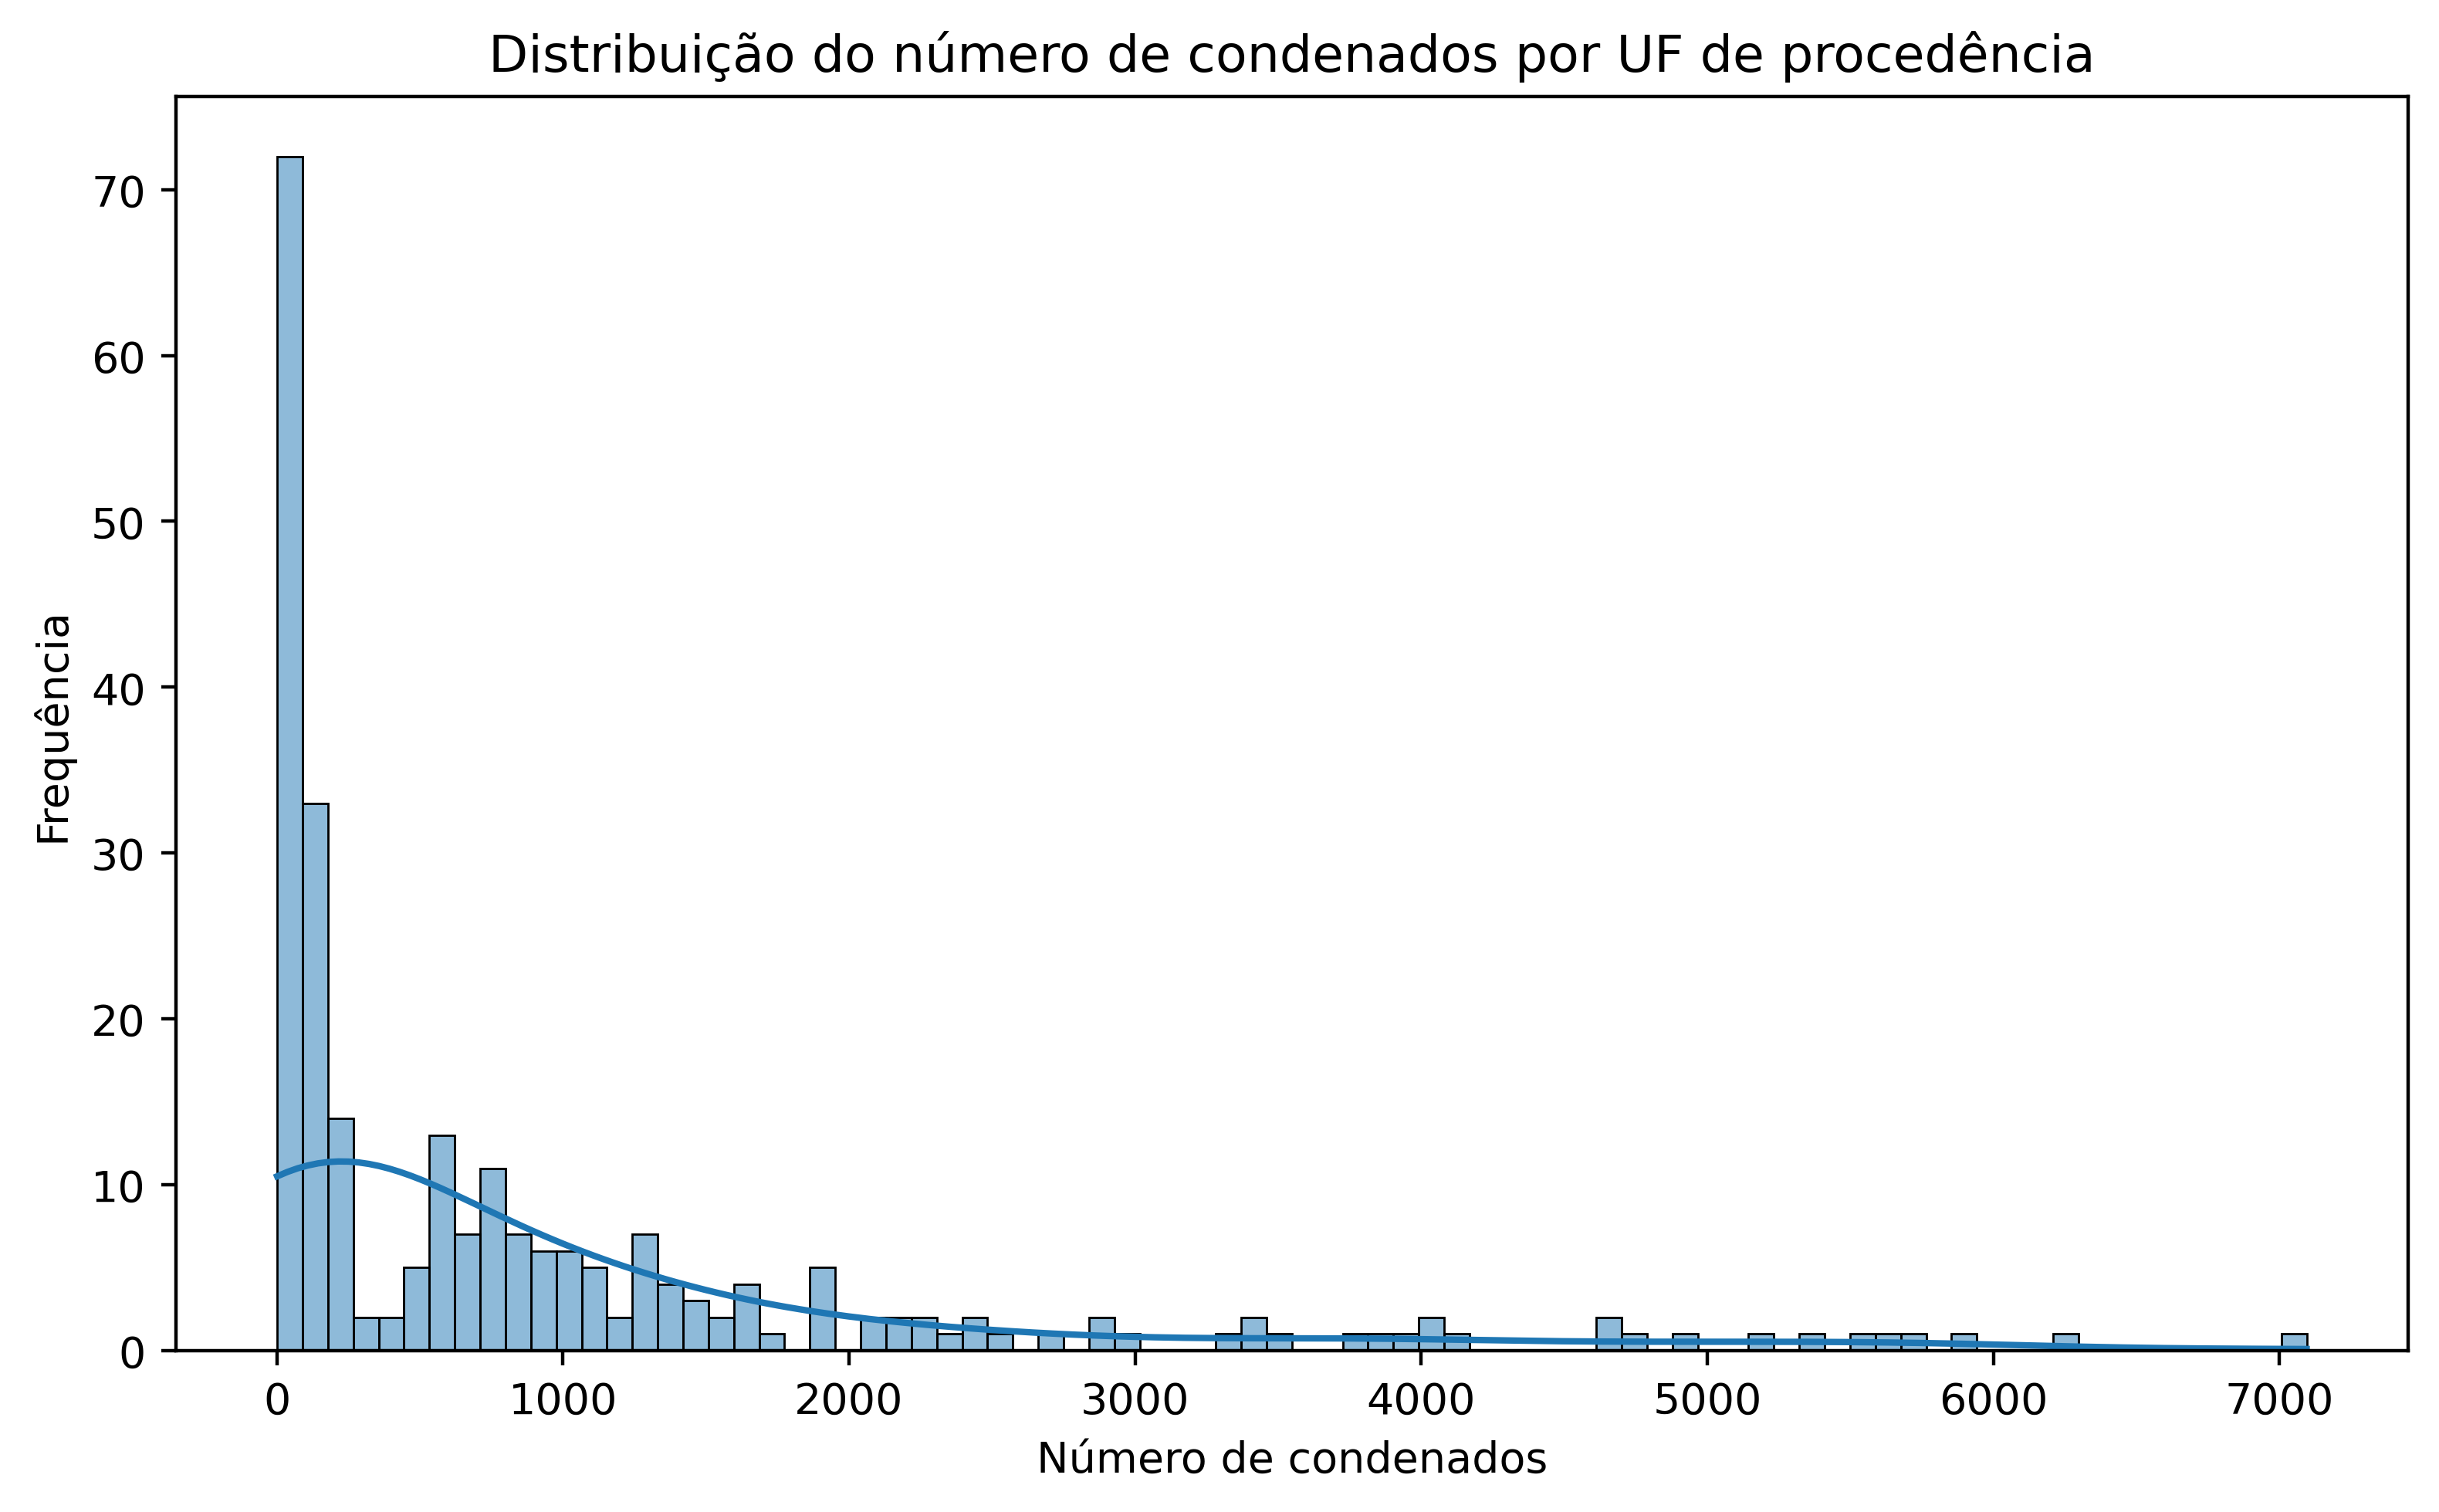

In [26]:
pl.figure(figsize=(8, 5))

sns.histplot(
    data=condenacao_consolidado,
    x="CONDENADO",
    bins=80,
    kde=True
)

pl.title("Distribuição do número de condenados por UF de procedência")
pl.xlabel("Número de condenados")
pl.ylabel("Frequência")
pl.tight_layout()
pl.show()

In [ ]:
from scipy.stats import shapiro

for uf, grupo in condenacao_consolidado.groupby("UF_PROCEDENCIA"):
    valores = grupo["CONDENADO"].dropna()

    estatistica, p_valor = shapiro(valores)

    print(
        f"{uf}: W = {estatistica:.4f}; "
        f"p = {p_valor:.4f}"
    )
    #os dados sendo p < 0,05 apresentam evidências suficientes para rejeitar a hipótese nula de normalidade, indicando que os dados não seguem uma distribuição normal.

ES: W = 0.9160; p = 0.0005
MG: W = 0.8518; p = 0.0000
RJ: W = 0.6575; p = 0.0000
SP: W = 0.8631; p = 0.0000


In [29]:
abate_consolidado = df_estat_bovino_abate_sudeste_bov.groupby(['ANO', 'MES', 'UF_PROCEDENCIA'], as_index=False).agg(ABATE=("QUANTIDADE", "sum"))
abate_consolidado

,ANO,MES,UF_PROCEDENCIA,ABATE
0,2021,1,ES,4230
1,2021,1,MG,121602
2,2021,1,RJ,2169
3,2021,1,SP,159299
4,2021,2,ES,5178
...,...,...,...,...
248,2026,3,ES,4364
249,2026,3,MG,188057
250,2026,3,RJ,1554
251,2026,3,SP,246487


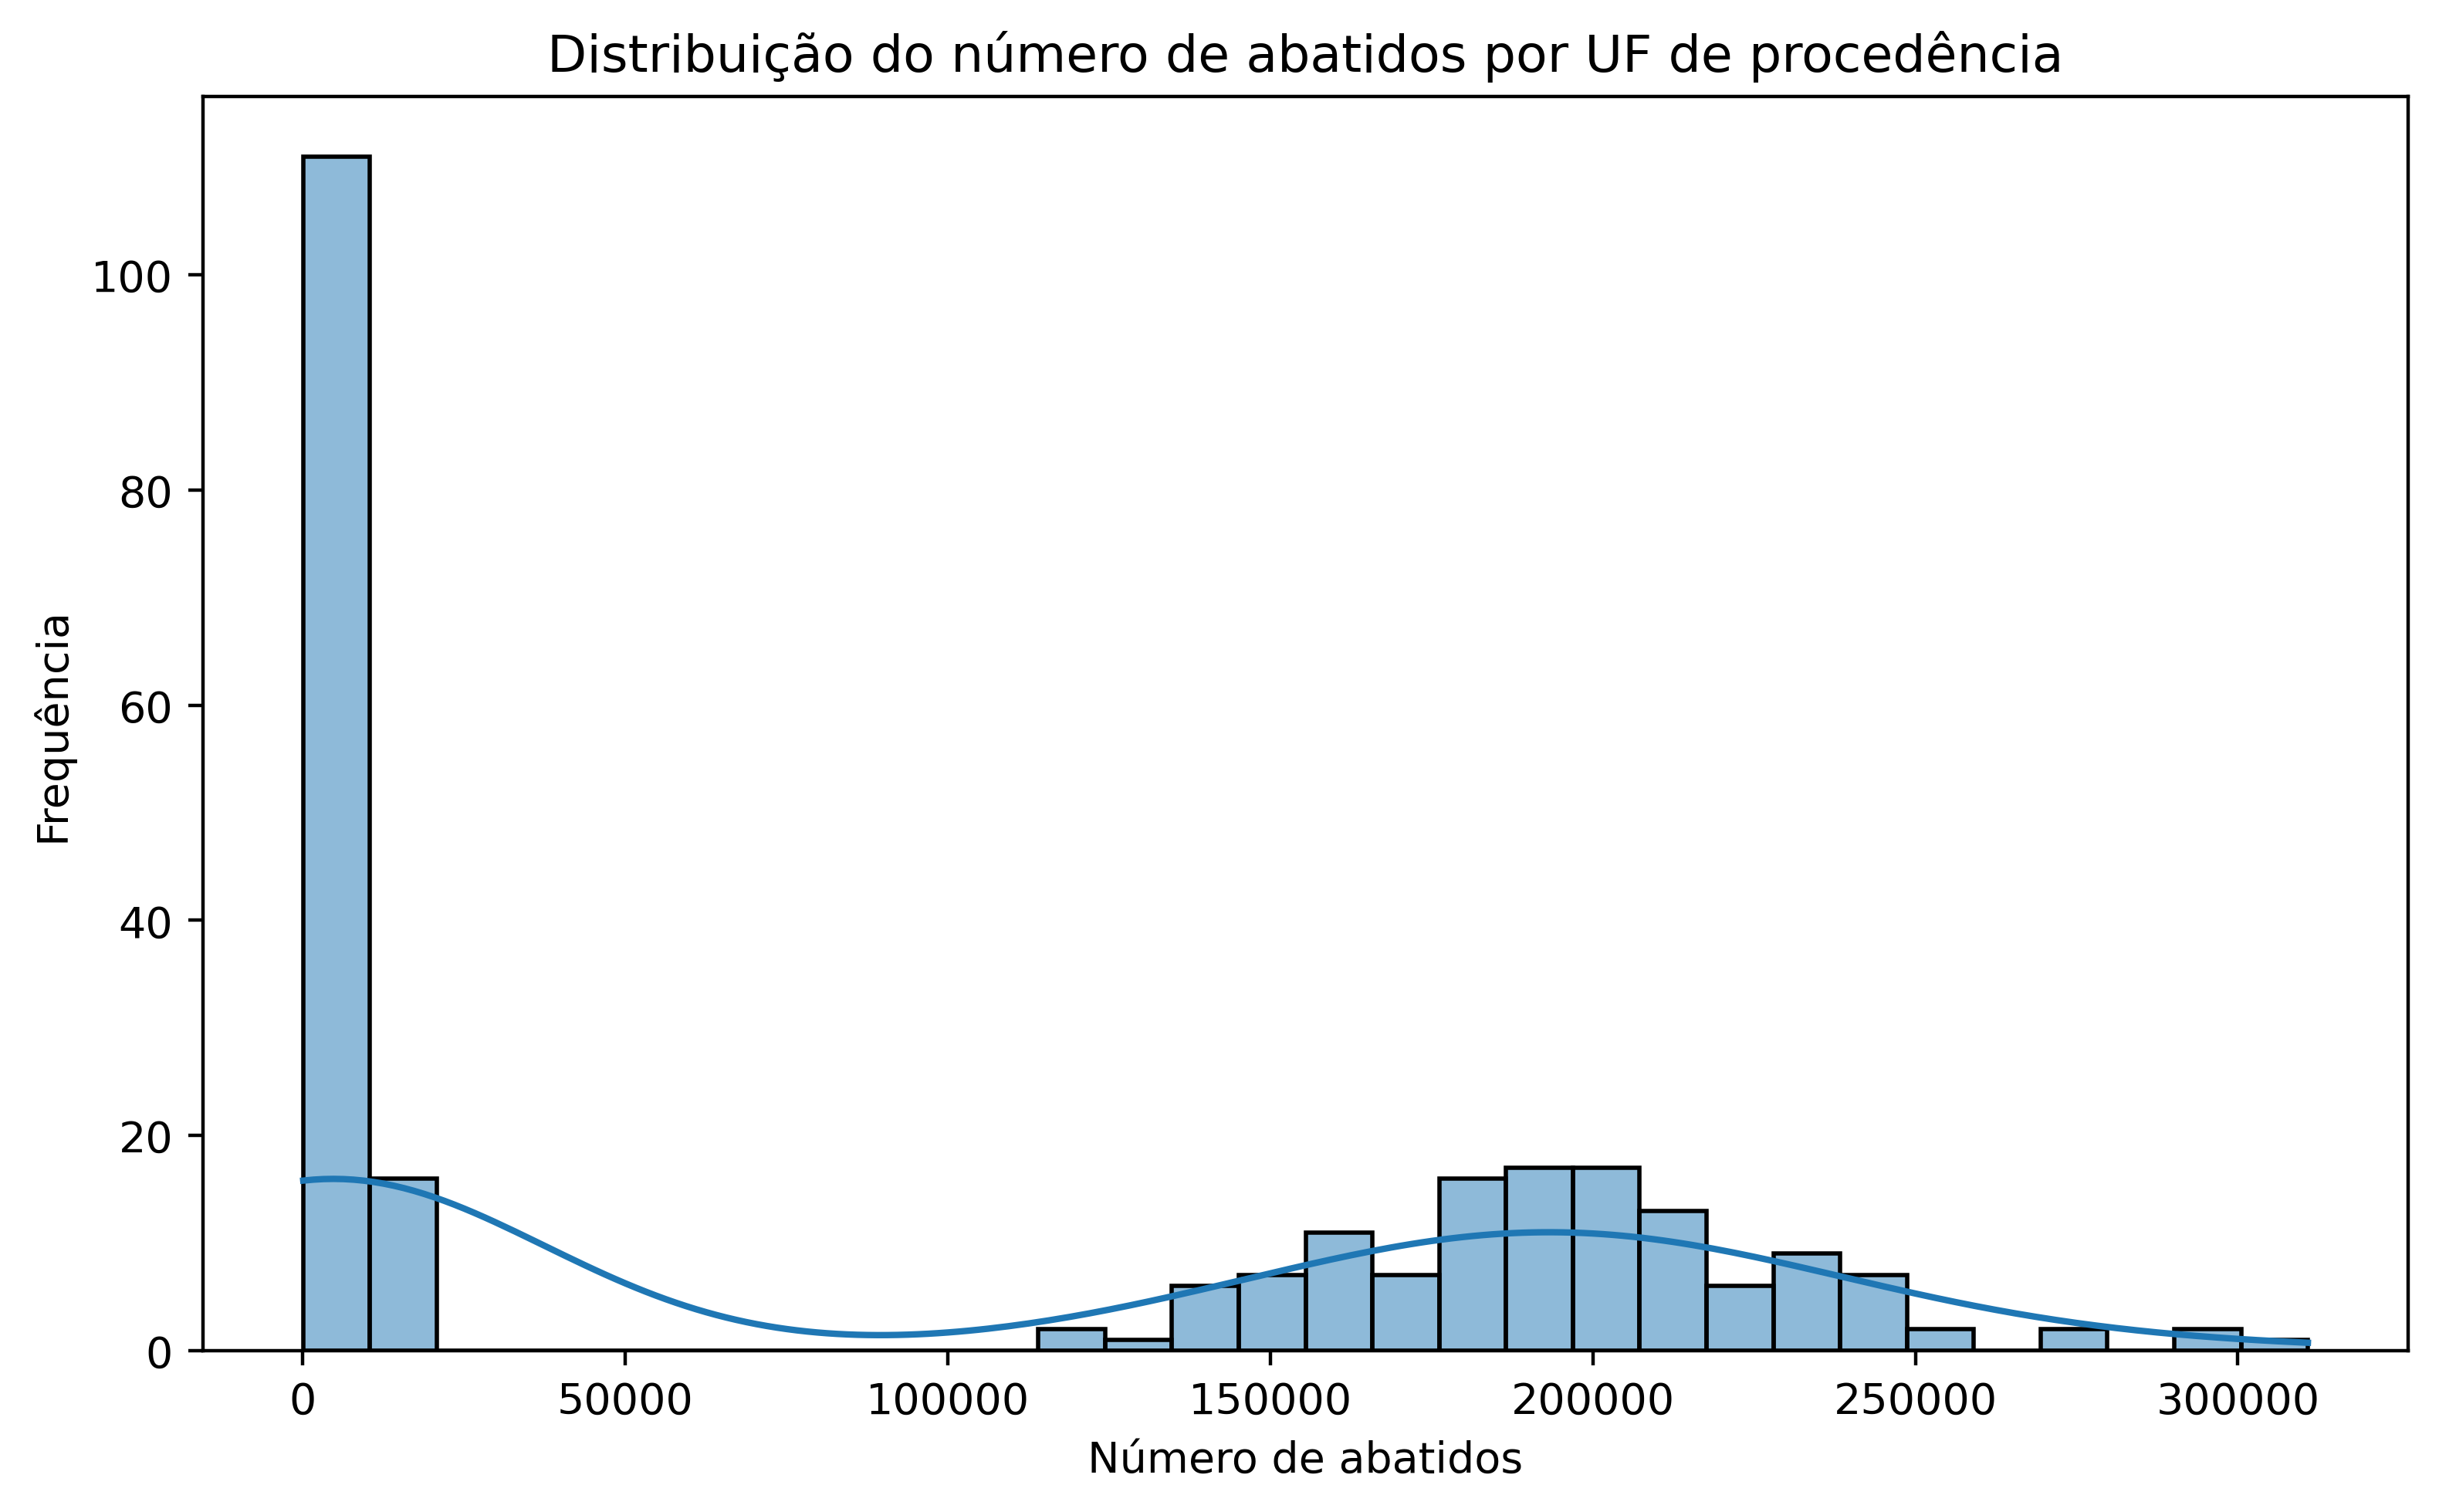

In [30]:
pl.figure(figsize=(8, 5))

sns.histplot(
    data=abate_consolidado,
    x="ABATE",
    bins=30,
    kde=True
)

pl.title("Distribuição do número de abatidos por UF de procedência")
pl.xlabel("Número de abatidos")
pl.ylabel("Frequência")
pl.tight_layout()
pl.show()

In [31]:
from scipy.stats import shapiro

for uf, grupo in abate_consolidado.groupby("UF_PROCEDENCIA"):
    valores = grupo["ABATE"].dropna()

    estatistica, p_valor = shapiro(valores)

    print(
        f"{uf}: W = {estatistica:.4f}; "
        f"p = {p_valor:.4f}"
    )

ES: W = 0.9466; p = 0.0085
MG: W = 0.7856; p = 0.0000
RJ: W = 0.9695; p = 0.1202
SP: W = 0.9771; p = 0.2893


In [32]:
dados_estat = pd.merge(condenacao_consolidado, abate_consolidado, on=['ANO', 'MES', 'UF_PROCEDENCIA'], how='right', validate='one_to_one')
dados_estat["percentual_condenados"] = (
    dados_estat["CONDENADO"] / dados_estat["ABATE"] * 100
).fillna(0)

#dados_estat["ABATE"] = dados_estat["ABATE"].fillna(0)
dados_estat["CONDENADO"] = dados_estat["CONDENADO"].fillna(0)

print(dados_estat.head(100))
dados_estat.to_excel("tabela_dadosestat.xlsx", index=False)

     ANO  MES UF_PROCEDENCIA  CONDENADO   ABATE  percentual_condenados
0   2021    1             ES        0.0    4230               0.000000
1   2021    1             MG        0.0  121602               0.000000
2   2021    1             RJ        0.0    2169               0.000000
3   2021    1             SP        0.0  159299               0.000000
4   2021    2             ES      124.0    5178               2.394747
..   ...  ...            ...        ...     ...                    ...
95  2022   12             SP      774.0  201885               0.383387
96  2023    1             ES      109.0    2842               3.835327
97  2023    1             MG      635.0  147402               0.430795
98  2023    1             RJ        8.0    2253               0.355082
99  2023    1             SP      815.0  195162               0.417602

[100 rows x 6 columns]


In [34]:
from scipy.stats import shapiro

for uf, grupo in dados_estat.groupby("UF_PROCEDENCIA"):
    valores = grupo["percentual_condenados"].dropna()

    estatistica, p_valor = shapiro(valores)

    print(
        f"{uf}: W = {estatistica:.4f}; "
        f"p = {p_valor:.4f}"
    )

ES: W = 0.9560; p = 0.0244
MG: W = 0.8791; p = 0.0000
RJ: W = 0.7159; p = 0.0000
SP: W = 0.8429; p = 0.0000


In [35]:
modelo_quasi = smf.glm(
    "CONDENADO + I(ABATE - CONDENADO) ~ C(UF_PROCEDENCIA) + C(ANO)",
    data=dados_estat,
    family=sm.families.Binomial()
).fit(scale="X2")

print(modelo_quasi.summary())

                           Generalized Linear Model Regression Results                           
Dep. Variable:     ['CONDENADO', 'I(ABATE - CONDENADO)']   No. Observations:                  253
Model:                                               GLM   Df Residuals:                      244
Model Family:                                   Binomial   Df Model:                            8
Link Function:                                     Logit   Scale:                        0.015929
Method:                                             IRLS   Log-Likelihood:                -21607.
Date:                                   Wed, 19 Aug 2026   Deviance:                       41390.
Time:                                           16:20:17   Pearson chi2:                 4.39e+04
No. Iterations:                                       13   Pseudo R-squ. (CS):              1.000
Covariance Type:                               nonrobust                                         
                    

<h2>TESTE DE FRIEDMAN E WILCOXON<H2>

<H3>BASE PARA O CÁLCULO<H3>

In [41]:
dados_mes = abate_consolidado.merge(
    condenacao_consolidado,
    on=["ANO", "MES", "UF_PROCEDENCIA"],
    how="left",
    validate="one_to_one"
)

# Use somente se ausência de registro de condenação significar zero real
dados_mes["CONDENADO"] = dados_mes["CONDENADO"].fillna(0)

dados_mes["percentual_condenados"] = (
    dados_mes["CONDENADO"] / dados_mes["ABATE"] * 100
)

dados_mes

,ANO,MES,UF_PROCEDENCIA,ABATE,CONDENADO,percentual_condenados
0,2021,1,ES,4230,0.0,0.000000
1,2021,1,MG,121602,0.0,0.000000
2,2021,1,RJ,2169,0.0,0.000000
3,2021,1,SP,159299,0.0,0.000000
4,2021,2,ES,5178,124.0,2.394747
...,...,...,...,...,...,...
248,2026,3,ES,4364,4.0,0.091659
249,2026,3,MG,188057,2869.0,1.525601
250,2026,3,RJ,1554,66.0,4.247104
251,2026,3,SP,246487,2702.0,1.096204


In [43]:
ano = 2021

painel_2021 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2021[uf] for uf in painel_2021.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(21.109090909090934), pvalue=np.float64(9.992458099432223e-05))


In [54]:
ano = 2021

painel_2021 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultados = []

for uf1, uf2 in combinations(painel_2021.columns, 2):
    teste = wilcoxon(
        painel_2021[uf1],
        painel_2021[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "ano": ano,
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (painel_2021[uf1] - painel_2021[uf2]).median()
    })

pos_hoc = pd.DataFrame(resultados)

# Ajusta os seis testes entre as quatro UFs
pos_hoc["p_holm"] = multipletests(
    pos_hoc["p_bruto"],
    method="holm"
)[1]

pos_hoc["significativo"] = pos_hoc["p_holm"] < 0.05

print(pos_hoc.round(4))

    ano comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0  2021    ES × MG   0.0010             1.5791  0.0059           True
1  2021    ES × RJ   0.0010             1.6458  0.0059           True
2  2021    ES × SP   0.0010             1.6682  0.0059           True
3  2021    MG × RJ   0.7051             0.0617  1.0000          False
4  2021    MG × SP   0.0234             0.1220  0.0703          False
5  2021    RJ × SP   0.8203            -0.0264  1.0000          False


In [63]:
dados_mes["indice_condenacoes"] = (
    dados_mes["CONDENADO"] / dados_mes["ABATE"] * 100
)

ano = 2021

painel_indice = dados_mes.loc[
    dados_mes["ANO"] == ano,
    ["ANO", "UF_PROCEDENCIA", "indice_condenacoes"]
].dropna()

resumo_anual_uf = (
    painel_indice
    .groupby(["ANO", "UF_PROCEDENCIA"], as_index=False)
    .agg(
        mediana_indice=("indice_condenacoes", "median"),
        minimo_indice=("indice_condenacoes", "min"),
        maximo_indice=("indice_condenacoes", "max")
    )
    .sort_values("mediana_indice", ascending=False)
)

print(resumo_anual_uf)

    ANO UF_PROCEDENCIA  mediana_indice  minimo_indice  maximo_indice
0  2021             ES        2.060535            0.0       3.252351
1  2021             MG        0.508991            0.0       0.709120
3  2021             SP        0.370981            0.0       0.501495
2  2021             RJ        0.338759            0.0       1.954216


In [44]:
ano = 2022

painel_2022 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2022[uf] for uf in painel_2022.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(23.700000000000017), pvalue=np.float64(2.8854213459568084e-05))


In [55]:
ano = 2022

painel_2022 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultados = []

for uf1, uf2 in combinations(painel_2022.columns, 2):
    teste = wilcoxon(
        painel_2022[uf1],
        painel_2022[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "ano": ano,
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (painel_2022[uf1] - painel_2022[uf2]).median()
    })

pos_hoc = pd.DataFrame(resultados)

# Ajusta os seis testes entre as quatro UFs
pos_hoc["p_holm"] = multipletests(
    pos_hoc["p_bruto"],
    method="holm"
)[1]

pos_hoc["significativo"] = pos_hoc["p_holm"] < 0.05

print(pos_hoc.round(4))

    ano comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0  2022    ES × MG   0.0005             1.3418  0.0029           True
1  2022    ES × RJ   0.0005             1.3985  0.0029           True
2  2022    ES × SP   0.0005             1.3252  0.0029           True
3  2022    MG × RJ   0.5693             0.0596  0.5693          False
4  2022    MG × SP   0.1514            -0.0619  0.4541          False
5  2022    RJ × SP   0.2334            -0.1224  0.4668          False


In [45]:
ano = 2023

painel_2023 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2023[uf] for uf in painel_2023.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(25.900000000000006), pvalue=np.float64(1.0008437984127522e-05))


In [56]:
ano = 2023

painel_2023 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultados = []

for uf1, uf2 in combinations(painel_2023.columns, 2):
    teste = wilcoxon(
        painel_2023[uf1],
        painel_2023[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "ano": ano,
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (painel_2023[uf1] - painel_2023[uf2]).median()
    })

pos_hoc = pd.DataFrame(resultados)

# Ajusta os seis testes entre as quatro UFs
pos_hoc["p_holm"] = multipletests(
    pos_hoc["p_bruto"],
    method="holm"
)[1]

pos_hoc["significativo"] = pos_hoc["p_holm"] < 0.05

print(pos_hoc.round(4))

    ano comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0  2023    ES × MG   0.0005             1.6332  0.0029           True
1  2023    ES × RJ   0.0005             2.0499  0.0029           True
2  2023    ES × SP   0.0005             1.8031  0.0029           True
3  2023    MG × RJ   0.0640             0.2218  0.1279          False
4  2023    MG × SP   0.0269             0.1523  0.0806          False
5  2023    RJ × SP   0.2334            -0.1205  0.2334          False


In [46]:
ano = 2024

painel_2024 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2024[uf] for uf in painel_2024.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(32.400000000000006), pvalue=np.float64(4.309970938885195e-07))


In [57]:
ano = 2024

painel_2024 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultados = []

for uf1, uf2 in combinations(painel_2024.columns, 2):
    teste = wilcoxon(
        painel_2024[uf1],
        painel_2024[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "ano": ano,
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (painel_2024[uf1] - painel_2024[uf2]).median()
    })

pos_hoc = pd.DataFrame(resultados)

# Ajusta os seis testes entre as quatro UFs
pos_hoc["p_holm"] = multipletests(
    pos_hoc["p_bruto"],
    method="holm"
)[1]

pos_hoc["significativo"] = pos_hoc["p_holm"] < 0.05

print(pos_hoc.round(4))

    ano comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0  2024    ES × MG   0.4238            -0.4702  0.4238          False
1  2024    ES × RJ   0.0005            -6.6430  0.0029           True
2  2024    ES × SP   0.0005             0.9486  0.0029           True
3  2024    MG × RJ   0.0005            -6.7360  0.0029           True
4  2024    MG × SP   0.0005             1.1458  0.0029           True
5  2024    RJ × SP   0.0005             7.8098  0.0029           True


In [47]:
ano = 2025

painel_2025 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2025[uf] for uf in painel_2025.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(29.700000000000017), pvalue=np.float64(1.5958502002852028e-06))


In [58]:
ano = 2025

painel_2025 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultados = []

for uf1, uf2 in combinations(painel_2025.columns, 2):
    teste = wilcoxon(
        painel_2025[uf1],
        painel_2025[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "ano": ano,
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (painel_2025[uf1] - painel_2025[uf2]).median()
    })

pos_hoc = pd.DataFrame(resultados)

# Ajusta os seis testes entre as quatro UFs
pos_hoc["p_holm"] = multipletests(
    pos_hoc["p_bruto"],
    method="holm"
)[1]

pos_hoc["significativo"] = pos_hoc["p_holm"] < 0.05

print(pos_hoc.round(4))

    ano comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0  2025    ES × MG   0.0005            -1.6392  0.0029           True
1  2025    ES × RJ   0.0005            -3.0661  0.0029           True
2  2025    ES × SP   0.8501            -0.0107  0.8501          False
3  2025    MG × RJ   0.0342            -1.6415  0.0684          False
4  2025    MG × SP   0.0005             1.5599  0.0029           True
5  2025    RJ × SP   0.0005             3.3134  0.0029           True


In [48]:
ano = 2026

painel_2026 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2026[uf] for uf in painel_2026.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(8.200000000000003), pvalue=np.float64(0.04205418289496618))


In [49]:
ano = 2026

painel_2026 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultados = []

for uf1, uf2 in combinations(painel_2026.columns, 2):
    teste = wilcoxon(
        painel_2026[uf1],
        painel_2026[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "ano": ano,
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (painel_2026[uf1] - painel_2026[uf2]).median()
    })

pos_hoc = pd.DataFrame(resultados)

# Ajusta os seis testes entre as quatro UFs
pos_hoc["p_holm"] = multipletests(
    pos_hoc["p_bruto"],
    method="holm"
)[1]

pos_hoc["significativo"] = pos_hoc["p_holm"] < 0.05

print(pos_hoc.round(4))

    ano comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0  2026    ES × MG     0.25            -1.6485     1.0          False
1  2026    ES × RJ     0.25            -2.3316     1.0          False
2  2026    ES × SP     0.25            -1.0045     1.0          False
3  2026    MG × RJ     0.75            -0.5019     1.0          False
4  2026    MG × SP     0.25             0.4294     1.0          False
5  2026    RJ × SP     0.25             0.5927     1.0          False
